<font color="#6E6E6E"><h2 align="left">Módulo Anomalias</h2></font>
<font color="#6E6E6E"><h2 align="left">Ejemplo básico Pyod</h2></font>

#### Valero Laparra


In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Instalamos Pyod
!pip install pyod

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.6/169.6 kB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pyod: filename=pyod-2.0.3-py3-none-any.whl size=200466 sha256=16398c510c3c87ca59901db29979371f2c785d56618e5000ababce352cefd694
  Stored in directory: /root/.cache/pip/wheels/2d/60/5b/f74eccd2c9c892a2c298202ca510f10995f9940647fcc2d97f
Successfully built pyod


## Datos

In [3]:
# Leemos IRIS
from sklearn.datasets import load_iris
X, y = load_iris(return_X_y=True)


In [4]:
print(X.shape)
print(y.shape)

(150, 4)
(150,)


## Anomaly detection

In [5]:
# Leemos un algoritmo: ECOD detector
from pyod.models.ecod import ECOD

In [6]:
# Creamos el modelo
clf = ECOD()
# Entrenamos
clf.fit(X)

ECOD(contamination=0.1, n_jobs=1)

In [7]:
# Evaluamos el modelo
y_train_scores = clf.decision_function(X)
# En train se puede usar:
# y_train_scores = clf.decision_scores_

In [8]:
y_train_scores

array([ 6.40567893,  5.82824376,  7.69503842,  6.50334554,  6.92795194,
        6.55713597,  7.34277279,  5.82860892,  7.90878119,  7.52645028,
        6.24596882,  6.34848438,  8.0636201 , 13.32111548,  9.39978651,
        8.26996281,  8.0304417 ,  6.21846739,  5.68240201,  6.51957248,
        5.08281801,  6.13879999, 11.3745171 ,  4.80474768,  6.22065101,
        4.84741451,  5.31049672,  5.87972442,  5.92054642,  6.30874405,
        5.75470968,  4.99826062,  9.91691057,  8.5674422 ,  5.60952767,
        7.6387987 ,  6.82187211,  9.219568  ,  8.31315041,  5.58077276,
        7.24646211, 10.24219438,  8.70663933,  5.66171681,  6.06083844,
        5.95948595,  6.5335123 ,  7.11555055,  6.36857114,  6.1111908 ,
        5.08122945,  3.85795691,  4.9139265 ,  5.33919862,  4.3350277 ,
        3.28254543,  4.30392715,  6.54026027,  4.09844897,  4.35183114,
        8.52642082,  2.9258628 ,  6.21884819,  3.51760536,  3.44304212,
        3.91148981,  3.02775034,  3.92507042,  6.22735067,  4.71

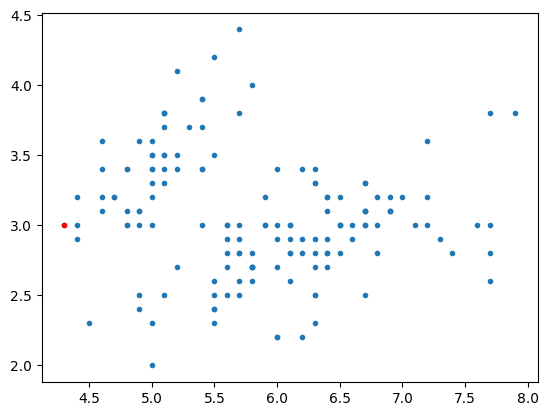

In [9]:
plt.plot(X[:,0],X[:,1],'.')

ii = np.argmax(y_train_scores)
plt.plot(X[ii,0],X[ii,1],'r.')

(0.705, 7.195, -0.01999999999999999, 2.62)

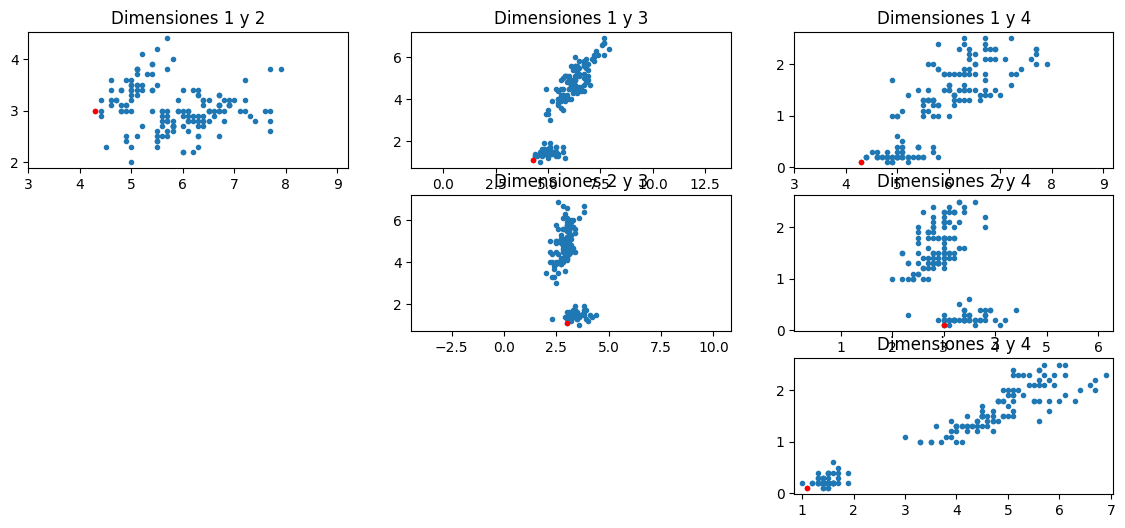

In [10]:
# Mostramos las combinaciones de dimensiones 2 a 2
plt.figure(figsize=(14,6))
plt.subplot(3,3,1), plt.plot(X[:,0],X[:,1],'.'), plt.title('Dimensiones 1 y 2')
plt.subplot(3,3,1), plt.plot(X[ii,0],X[ii,1],'r.'), plt.title('Dimensiones 1 y 2')
plt.axis('equal')
plt.subplot(3,3,2), plt.plot(X[:,0],X[:,2],'.'), plt.title('Dimensiones 1 y 3')
plt.subplot(3,3,2), plt.plot(X[ii,0],X[ii,2],'r.'), plt.title('Dimensiones 1 y 3')
plt.axis('equal')
plt.subplot(3,3,3), plt.plot(X[:,0],X[:,3],'.'), plt.title('Dimensiones 1 y 4')
plt.subplot(3,3,3), plt.plot(X[ii,0],X[ii,3],'r.'), plt.title('Dimensiones 1 y 4')
plt.axis('equal')
plt.subplot(3,3,5), plt.plot(X[:,1],X[:,2],'.'), plt.title('Dimensiones 2 y 3')
plt.subplot(3,3,5), plt.plot(X[ii,1],X[ii,2],'r.'), plt.title('Dimensiones 2 y 3')
plt.axis('equal')
plt.subplot(3,3,6), plt.plot(X[:,1],X[:,3],'.'), plt.title('Dimensiones 2 y 4')
plt.subplot(3,3,6), plt.plot(X[ii,1],X[ii,3],'r.'), plt.title('Dimensiones 2 y 4')
plt.axis('equal')
plt.subplot(3,3,9), plt.plot(X[:,2],X[:,3],'.'), plt.title('Dimensiones 3 y 4')
plt.subplot(3,3,9), plt.plot(X[ii,2],X[ii,3],'r.'), plt.title('Dimensiones 3 y 4')
plt.axis('equal')

**Ejercicio:**
- Compara los algoritmos: GMM, DBSCAN, LOF, Isolation Forest... otros

https://pyod.readthedocs.io/en/latest/pyod.models.html

**Ejercicio:**
- Cambia el código para mostrar varias anomalias y compara los métodos